# Heart Disease Prediction

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Question:** Using routine clinical measurements, how well can we classify whether a patient has heart disease, and which measurements matter most?

**Data:** UCI Cleveland Heart Disease dataset (303 patients, 13 clinical features). Public and widely used for teaching.

**Approach**
1. Inspect and clean the data (hidden missing values, target definition)
2. Explore differences between patients with and without disease
3. Build leak-free pipelines and compare k-NN with logistic regression and random forest using cross-validation
4. Tune k for k-NN and evaluate once on a held-out test set
5. Interpret the model and state its limits

> This is an educational project, **not a diagnostic tool**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import UndefinedMetricWarning; warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, ORANGE = "#0f766e", "#365bd6", "#c2410c"

COLUMNS = ["age", "sex", "chest_pain_type", "resting_bp", "cholesterol", "fasting_blood_sugar",
           "resting_ecg", "max_heart_rate", "exercise_angina", "st_depression", "st_slope",
           "major_vessels", "thalassemia", "diagnosis"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
heart = pd.read_csv(URL, header=None, names=COLUMNS, na_values="?")
print(heart.shape)
heart.head()

(303, 14)


,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thalassemia,diagnosis
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Inspect and clean
Missing values are stored as `?` in the raw file. The original `diagnosis` column runs from 0 (no disease) to 4; it is converted to a binary target: **0 = no disease, 1 = disease present**.

In [2]:
print("Missing values:\n", heart.isna().sum()[heart.isna().sum() > 0])
heart["disease"] = (heart["diagnosis"] > 0).astype(int)
heart = heart.drop(columns="diagnosis")
print(f"\nDisease prevalence: {heart['disease'].mean():.1%} of {len(heart)} patients")

Missing values:
 major_vessels    4
thalassemia      2
dtype: int64

Disease prevalence: 45.9% of 303 patients


## 2. Explore

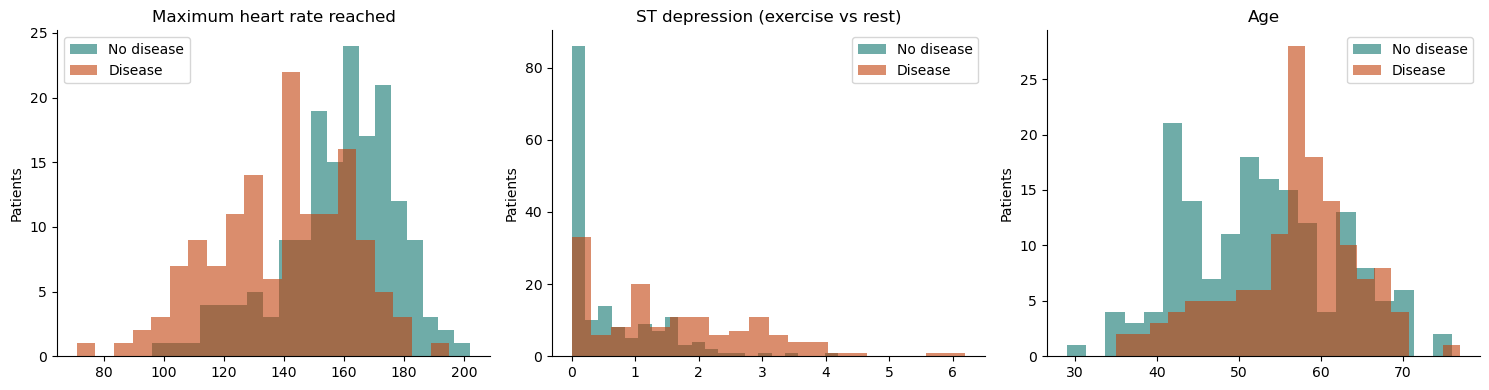

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["max_heart_rate", "st_depression", "age"],
                          ["Maximum heart rate reached", "ST depression (exercise vs rest)", "Age"]):
    for label, color, name in [(0, TEAL, "No disease"), (1, ORANGE, "Disease")]:
        ax.hist(heart.loc[heart.disease == label, col].dropna(), bins=20, alpha=0.6, color=color, label=name)
    ax.set(title=title, ylabel="Patients"); ax.legend()
plt.tight_layout(); plt.savefig("../images/feature_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

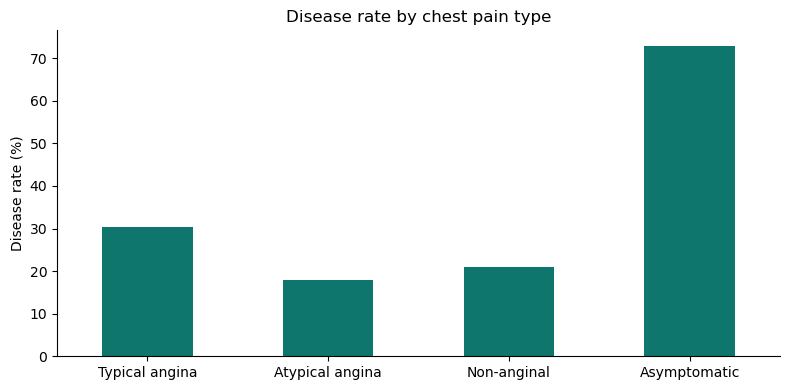

,Chest pain type
chest_pain_type,
Typical angina,30.4
Atypical angina,18.0
Non-anginal,20.9
Asymptomatic,72.9


In [4]:
rates = pd.DataFrame({
    "Chest pain type": heart.groupby("chest_pain_type")["disease"].mean(),
}).rename(index={1.0: "Typical angina", 2.0: "Atypical angina", 3.0: "Non-anginal", 4.0: "Asymptomatic"})
ax = rates["Chest pain type"].mul(100).plot.bar(color=TEAL, rot=0, figsize=(8, 4))
ax.set(title="Disease rate by chest pain type", ylabel="Disease rate (%)", xlabel="")
plt.tight_layout(); plt.savefig("../images/disease_by_chest_pain.png", dpi=150, bbox_inches="tight"); plt.show()
rates.mul(100).round(1)

Patients **without** typical chest pain (asymptomatic) have the highest disease rate, a counter-intuitive pattern that is well known in this dataset and a good reason to let the data, not assumptions, guide feature choice.

## 3. Leak-free pipelines and model comparison

In [5]:
X, y = heart.drop(columns="disease"), heart["disease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

numeric = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "major_vessels"]
categorical = ["sex", "chest_pain_type", "fasting_blood_sugar", "resting_ecg", "exercise_angina", "st_slope", "thalassemia"]
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}
rows = {}
for name, m in models.items():
    s = cross_validate(make_pipeline(prep, m), X_train, y_train, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows[name] = {k: s[f"test_{k}"].mean() for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
pd.DataFrame(rows).T.round(3).sort_values("roc_auc", ascending=False)

,accuracy,precision,recall,f1,roc_auc
Random forest,0.802,0.807,0.761,0.779,0.902
Logistic regression,0.806,0.806,0.770,0.784,0.899
k-NN (k=5),0.820,0.813,0.808,0.804,0.876
Baseline (majority class),0.542,0.000,0.000,0.000,0.500


## 4. Tune k for k-NN on training data only

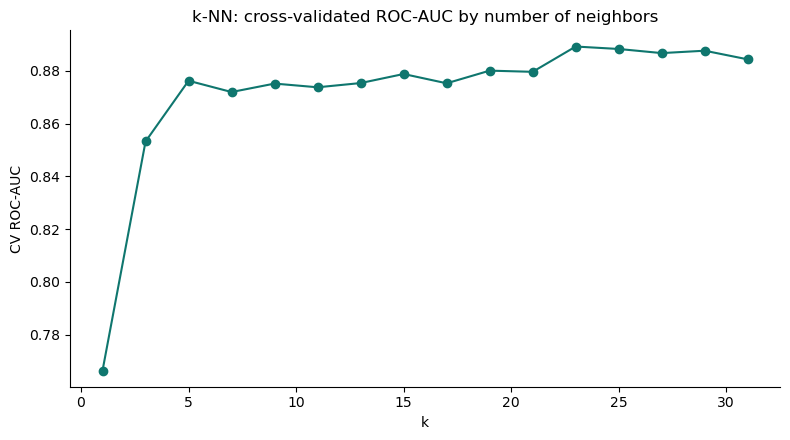

Best settings: {'kneighborsclassifier__n_neighbors': 25, 'kneighborsclassifier__weights': 'distance'} | CV ROC-AUC 0.893


In [6]:
search = GridSearchCV(make_pipeline(prep, KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": list(range(1, 32, 2)),
                       "kneighborsclassifier__weights": ["uniform", "distance"]},
                      cv=cv, scoring="roc_auc").fit(X_train, y_train)
res = pd.DataFrame(search.cv_results_)
uni = res[res["param_kneighborsclassifier__weights"] == "uniform"]
plt.plot(uni["param_kneighborsclassifier__n_neighbors"], uni["mean_test_score"], "o-", color=TEAL)
plt.title("k-NN: cross-validated ROC-AUC by number of neighbors"); plt.xlabel("k"); plt.ylabel("CV ROC-AUC")
plt.tight_layout(); plt.savefig("../images/knn_tuning.png", dpi=150, bbox_inches="tight"); plt.show()
print("Best settings:", search.best_params_, f"| CV ROC-AUC {search.best_score_:.3f}")

Very small *k* overfits (each patient is judged by one neighbor); performance stabilizes once *k* is large enough to average out noise.

## 5. Final evaluation on the held-out test set (used once)

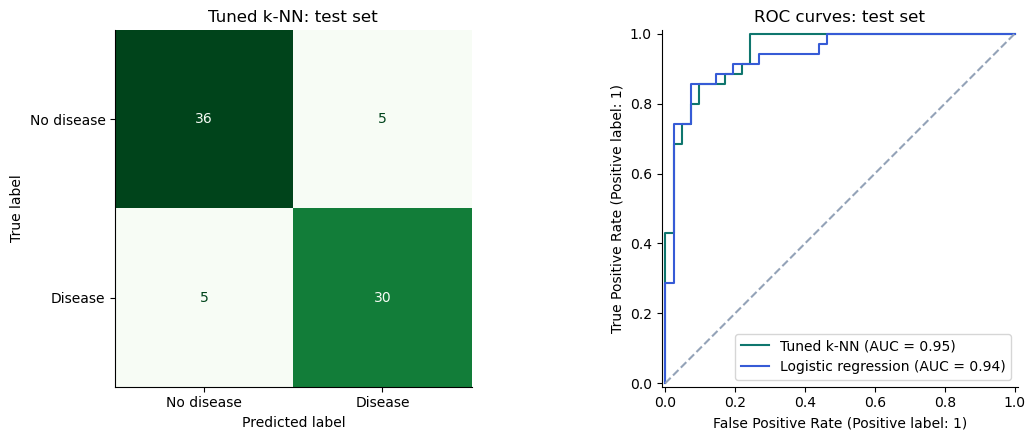

,accuracy,precision,recall (sensitivity),F1,ROC-AUC
Tuned k-NN,0.868,0.857,0.857,0.857,0.949
Logistic regression,0.855,0.833,0.857,0.845,0.937


In [7]:
final = {"Tuned k-NN": search.best_estimator_,
         "Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=2000)).fit(X_train, y_train)}
rows = {}
for name, m in final.items():
    p = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    rows[name] = {"accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                  "recall (sensitivity)": recall_score(y_test, p), "F1": f1_score(y_test, p),
                  "ROC-AUC": roc_auc_score(y_test, proba)}
test_table = pd.DataFrame(rows).T.round(3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(final["Tuned k-NN"], X_test, y_test, display_labels=["No disease", "Disease"],
                                      cmap="Greens", ax=axes[0], colorbar=False)
axes[0].set_title("Tuned k-NN: test set")
for (name, m), color in zip(final.items(), [TEAL, BLUE]):
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1], color=color)
axes[1].plot([0, 1], [0, 1], "--", color="#94a3b8"); axes[1].set_title("ROC curves: test set")
plt.tight_layout(); plt.savefig("../images/test_evaluation.png", dpi=150, bbox_inches="tight"); plt.show()
test_table

## 6. What drives the predictions?
Permutation importance measures how much test-set ROC-AUC drops when each feature is shuffled.

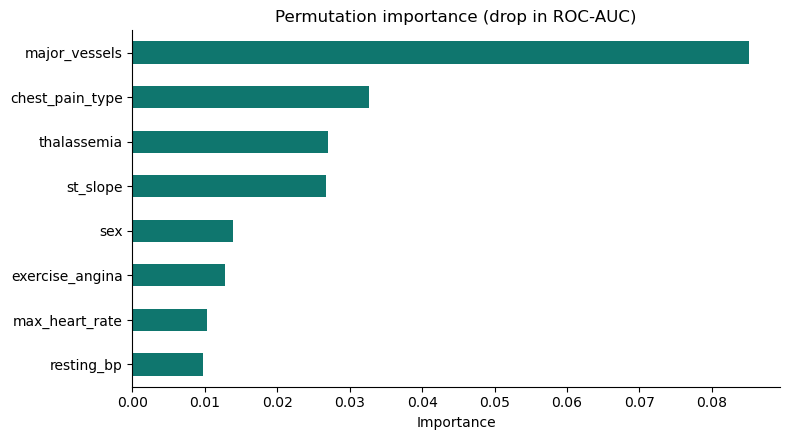

major_vessels      0.085
chest_pain_type    0.033
thalassemia        0.027
st_slope           0.027
sex                0.014
dtype: float64

In [8]:
imp = permutation_importance(final["Logistic regression"], X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
imp.tail(8).plot.barh(color=TEAL)
plt.title("Permutation importance (drop in ROC-AUC)"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).head(5).round(3)

## 7. Conclusions and limitations
- A tuned **k-NN** and a simple **logistic regression** both separate patients with and without disease well, and both are far above the baseline.
- The number of blocked **major vessels**, **thalassemia** test result, and **chest pain type** carry the most signal.
- With only 303 patients from one hospital (Cleveland, 1988), the model is small and dated. Results would need validation on new, diverse patients, and false negatives (missed disease) carry real clinical cost.

**This is an educational analysis and must not be used for diagnosis.**